In [1]:
import sys


sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

import torch,random
import fastcore.all as fc

from torch import nn
from torch.nn import init

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *

import pickle,gzip,math,os,time,shutil
import matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager

import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,optim
from torch.utils.data import DataLoader,default_collate
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

from fastcore.test import test_close
from torch import distributions

torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'

import logging
logging.disable(logging.WARNING)

set_seed(42)

if fc.defaults.cpus>8: fc.defaults.cpus=8


xl,yl = 'image','label'
name = "fashion_mnist"
bs = 1024
xmean,xstd = 0.28, 0.35

@inplace
def transformi(b): b[xl] = [(TF.to_tensor(o)-xmean)/xstd for o in b[xl]]

dsd = load_dataset(name)
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
class Accuracy100(MulticlassAccuracy):
    def compute(self):
        # Multiplies the final result by 100
        return super().compute() * 100 # here we overwrite the main function that makes the calculation but calling the original using super() , so we use the original but adjust it

# Use your new class
metrics = MetricsCB(accuracy=Accuracy100())

In [3]:
astats = ActivationStats(fc.risinstance(GeneralRelu))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
iw = partial(init_weights, leaky=0.1)

In [4]:
set_seed(42)
lr,epochs = 6e-2,5

# Going wider

In [5]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

changes: (bigger model)
- start at making 16 not 8 features (learning more features at the beggining)
- make `ks` 5 not 3 , get more from the image at each calc
- add the last features size to be 512 not 256

In [6]:
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

accuracy,loss,epoch,train
82.437,0.704,0,train
85.050,0.561,0,eval
89.823,0.381,1,train
89.170,0.367,1,eval
92.195,0.267,2,train
90.050,0.316,2,eval
94.045,0.199,3,train
92.460,0.242,3,eval
96.168,0.141,4,train
93.350,0.220,4,eval


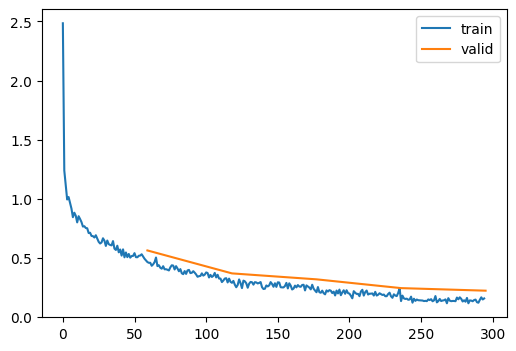

In [7]:
learn.fit(epochs)

# Pooling

In [8]:
class GlobalAvgPool(nn.Module):
    def forward(self, x): return x.mean((-2,-1)) # last 2 dimensions

In [9]:
def get_model2(act=nn.ReLU, nfs=(16,32,64,128,256), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [ResBlock(256, 512, act=act, norm=norm), GlobalAvgPool()]
    layers += [nn.Linear(512, 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

    Module	        Input	            Output	       Num params
    ResBlock  (2048, 1, 28, 28)	  (2048, 8, 28, 28)	712
    ResBlock  (2048, 8, 28, 28)	  (2048, 16, 14, 14)	3696
    ResBlock  (2048, 16, 14, 14)      (2048, 32, 7, 7)	14560
    ResBlock  (2048, 32, 7, 7)	  (2048, 64, 4, 4)	57792
    ResBlock  (2048, 64, 4, 4)	  (2048, 128, 2, 2) 	230272
    ResBlock  (2048, 128, 2, 2)	  (2048, 256, 1, 1) 	919296
    Flatten	  (2048, 256, 1, 1)	  (2048, 256)	        0
    Linear	  (2048, 256)	          (2048, 10)	        2560

idea is that at the part that we have (...,2,2) as output for the resnet , we just take the mean at this dimensions for this 4 pixels to 1 pixel (look down)

In [10]:
def _flops(x, h, w):
    if x.dim()<3: return x.numel()
    if x.dim()==4: return x.numel()*h*w

@fc.patch
def summary(self:Learner):
    res = '|Module|Input|Output|Num params|MFLOPS|\n|--|--|--|--|--|\n'
    totp,totf = 0,0
    def _f(hook, mod, inp, outp):
        nonlocal res,totp,totf
        nparms = sum(o.numel() for o in mod.parameters())
        totp += nparms
        *_,h,w = outp.shape
        flops = sum(_flops(o, h, w) for o in mod.parameters())/1e6 # 1e6->scale
        totf += flops
        res += f'|{type(mod).__name__}|{tuple(inp[0].shape)}|{tuple(outp.shape)}|{nparms}|{flops:.1f}|\n'
    with Hooks(self.model, _f) as hooks: self.fit(1, lr=1, cbs=SingleBatchCB())
    print(f"Tot params: {totp:,} | MFLOPS: {totf:.1f}")
    if fc.IN_NOTEBOOK:
        from IPython.display import Markdown
        return Markdown(res)
    else: print(res)

`nonlocal` = "use the variable from the outer function, not a new one"

At `_flop` amount of calculations (compute)

    non-conv (linear/bias): xdim<3
    each weight used ONCE → just count weights = numel()

    conv: xdim==4
    each kernel slides over h×w positions
    so calculations = kernel weights × h × w
     -> (h,w are the output ones not input ,[because each out pixel means
      that we had to slide the kernal and make a calculation to get it])

    both cases = total number of multiply-add operations ✓ [xw + xw -> 2
     operations]

In [11]:
TrainLearner(get_model2(), dls, F.cross_entropy, lr=lr, cbs=[DeviceCB()]).summary()

Tot params: 4,907,588 | MFLOPS: 33.0


|Module|Input|Output|Num params|MFLOPS|
|--|--|--|--|--|
|ResBlock|(1024, 1, 28, 28)|(1024, 16, 28, 28)|6928|5.3|
|ResBlock|(1024, 16, 28, 28)|(1024, 32, 14, 14)|14560|2.8|
|ResBlock|(1024, 32, 14, 14)|(1024, 64, 7, 7)|57792|2.8|
|ResBlock|(1024, 64, 7, 7)|(1024, 128, 4, 4)|230272|3.7|
|ResBlock|(1024, 128, 4, 4)|(1024, 256, 2, 2)|919296|3.7|
|ResBlock|(1024, 256, 2, 2)|(1024, 512, 2, 2)|3673600|14.7|
|GlobalAvgPool|(1024, 512, 2, 2)|(1024, 512)|0|0.0|
|Linear|(1024, 512)|(1024, 10)|5120|0.0|
|BatchNorm1d|(1024, 10)|(1024, 10)|20|0.0|


- NOTE: There is no relation between parameters and  speed (MFLOPS).
- NOTE: even the MFLOPS is not that accurate to the speed because it doesnt count other variables that are there that affect speed

accuracy,loss,epoch,train
82.203,0.715,0,train
86.170,0.537,0,eval
89.738,0.384,1,train
86.640,0.435,1,eval
91.850,0.271,2,train
91.050,0.283,2,eval
94.033,0.199,3,train
92.340,0.243,3,eval
96.148,0.143,4,train
93.140,0.224,4,eval


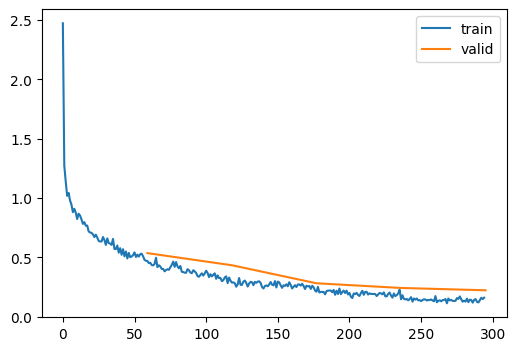

In [12]:
set_seed(42)
model = get_model2(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

In [13]:
def get_model3(act=nn.ReLU, nfs=(16,32,64,128,256), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [GlobalAvgPool(),nn.Linear(256, 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

In [14]:
TrainLearner(get_model3(), dls, F.cross_entropy, lr=lr, cbs=[DeviceCB()]).summary()

Tot params: 1,231,428 | MFLOPS: 18.3


|Module|Input|Output|Num params|MFLOPS|
|--|--|--|--|--|
|ResBlock|(1024, 1, 28, 28)|(1024, 16, 28, 28)|6928|5.3|
|ResBlock|(1024, 16, 28, 28)|(1024, 32, 14, 14)|14560|2.8|
|ResBlock|(1024, 32, 14, 14)|(1024, 64, 7, 7)|57792|2.8|
|ResBlock|(1024, 64, 7, 7)|(1024, 128, 4, 4)|230272|3.7|
|ResBlock|(1024, 128, 4, 4)|(1024, 256, 2, 2)|919296|3.7|
|GlobalAvgPool|(1024, 256, 2, 2)|(1024, 256)|0|0.0|
|Linear|(1024, 256)|(1024, 10)|2560|0.0|
|BatchNorm1d|(1024, 10)|(1024, 10)|20|0.0|


In [15]:
[o.shape for o in get_model3()[0].parameters()]

[torch.Size([16, 1, 5, 5]),
 torch.Size([16]),
 torch.Size([16]),
 torch.Size([16]),
 torch.Size([16, 16, 5, 5]),
 torch.Size([16]),
 torch.Size([16]),
 torch.Size([16]),
 torch.Size([16, 1, 1, 1]),
 torch.Size([16])]

- 2 of the 16 single tensors are beta and gamma of BatchNorm
- 1 of the 16 single tensors is conv bias (which doesnt matter because there is BatchNorm)

- there is 16  BN with seperate (gamma & beta) , because each channel needs its OWN scale and shift, because each one learned something different

accuracy,loss,epoch,train
81.055,0.758,0,train
84.120,0.548,0,eval
89.647,0.395,1,train
88.640,0.353,1,eval
91.753,0.278,2,train
90.040,0.325,2,eval
93.803,0.209,3,train
91.950,0.260,3,eval
95.875,0.154,4,train
92.470,0.236,4,eval


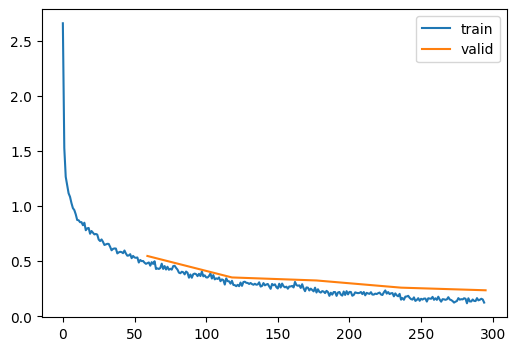

In [16]:
model = get_model3(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

In [17]:
def get_model4(act=nn.ReLU, nfs=(16,32,64,128,256), norm=nn.BatchNorm2d):
    layers = [conv(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [GlobalAvgPool(),nn.Linear(256, 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

replace the 1st resnet with a conv:
- fewer params , less compute MFLOPS
- simpler
- loses nothing meaningful ✓

In [18]:
TrainLearner(get_model4(), dls, F.cross_entropy, lr=lr, cbs=[DeviceCB()]).summary()

Tot params: 1,224,948 | MFLOPS: 13.3


|Module|Input|Output|Num params|MFLOPS|
|--|--|--|--|--|
|Sequential|(1024, 1, 28, 28)|(1024, 16, 28, 28)|448|0.3|
|ResBlock|(1024, 16, 28, 28)|(1024, 32, 14, 14)|14560|2.8|
|ResBlock|(1024, 32, 14, 14)|(1024, 64, 7, 7)|57792|2.8|
|ResBlock|(1024, 64, 7, 7)|(1024, 128, 4, 4)|230272|3.7|
|ResBlock|(1024, 128, 4, 4)|(1024, 256, 2, 2)|919296|3.7|
|GlobalAvgPool|(1024, 256, 2, 2)|(1024, 256)|0|0.0|
|Linear|(1024, 256)|(1024, 10)|2560|0.0|
|BatchNorm1d|(1024, 10)|(1024, 10)|20|0.0|


accuracy,loss,epoch,train
80.382,0.782,0,train
87.100,0.480,0,eval
89.840,0.391,1,train
89.550,0.363,1,eval
91.932,0.277,2,train
90.230,0.311,2,eval
94.093,0.201,3,train
92.080,0.245,3,eval
96.162,0.148,4,train
92.560,0.236,4,eval


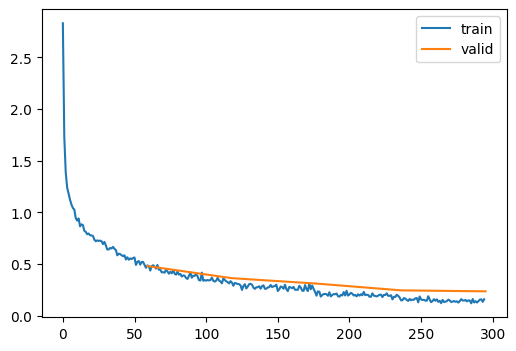

In [19]:
set_seed(42)
model = get_model4(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

# Data Augmentation

After 20 epochs without augmentation:

```
{'accuracy': '0.999', 'loss': '0.012', 'epoch': 19, 'train': True}
{'accuracy': '0.924', 'loss': '0.284', 'epoch': 19, 'train': False}
```

With batchnorm, weight decay doesn't really regularize.

    WHAT IS ACTUALLY HAPPENING:
    ─────────────────────────────────────────
    BN gamma multiplies everything after it
    so its gradient is massive and model updates it aggressively toward low loss

    conv weights also update
    but they adapt to WORK WITH BN gamma
    not the other way around

    BN gamma is the boss
    conv weights just serve it

    weight decay pushes conv small → fine, BN covers it
    weight decay pushes BN gamma small → gradient fights back
                                          and wins
                                          because BN gamma
                                          gradient is too huge
    -------------------------------------------------
    BN gamma touches every single output
    so its gradient is huge

    weight decay is designed for small corrections
    it is a gentle push toward small weights

    but when gradient is huge:
    gradient update  = huge step toward low loss
    weight decay     = tiny push back

    tiny push vs huge step = tiny push loses ✗

    BN gamma ends up large no matter what
    weight decay cannot compete with it ✓

In [20]:
from torchvision import transforms

In [21]:
def tfm_batch(b,t_x=fc.noop,t_y=fc.noop): return t_x(b[0]),t_y(b[1])

In [24]:
tfms = nn.Sequential(transforms.RandomCrop(28, padding=4),
                     transforms.RandomHorizontalFlip())
augcb = BatchTransformCB(partial(tfm_batch,t_x=tfms), on_val=False)
model = get_model()
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=[SingleBatchCB(), augcb])

In [25]:
learn.fit(1)

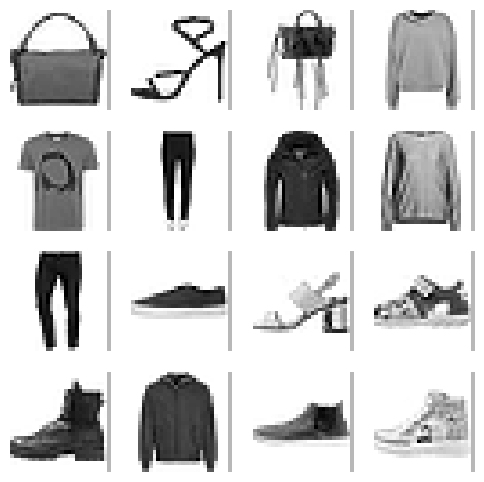

In [26]:
# see the batch
xb,yb = learn.batch
show_images(xb[:16], imsize=1.5)
# make a show Batch image fn and make the singe batch fit
@fc.patch
@fc.delegates(show_images)
def show_image_batch(self:Learner, max_n=9, cbs=None, **kwargs):
    self.fit(1, cbs=[SingleBatchCB()]+fc.L(cbs))
    show_images(self.batch[0][:max_n], **kwargs)

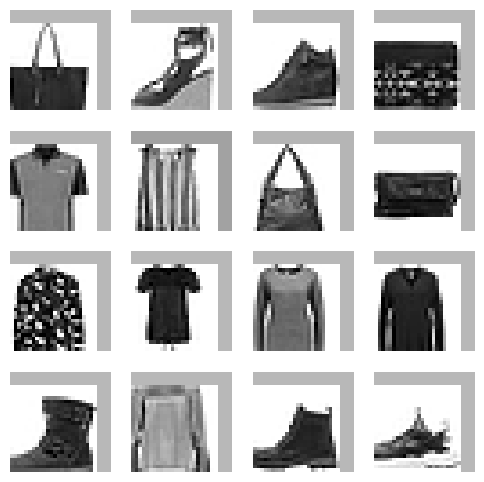

In [27]:
learn.show_image_batch(max_n=16, imsize=(1.5))

In [28]:
tfms = nn.Sequential(transforms.RandomCrop(28, padding=1),
                     transforms.RandomHorizontalFlip())
augcb = BatchTransformCB(partial(tfm_batch, t_x=tfms), on_val=False)

accuracy,loss,epoch,train
76.918,0.870,0,train
84.110,0.564,0,eval
86.262,0.577,1,train
86.330,0.506,1,eval
87.477,0.483,2,train
87.470,0.404,2,eval
88.705,0.390,3,train
86.700,0.404,3,eval
89.672,0.330,4,train
89.020,0.344,4,eval


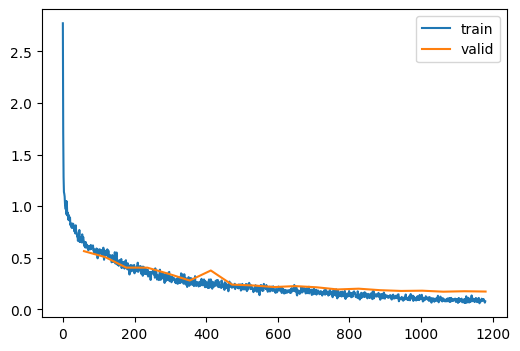

In [29]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

# Test time augmentation TTA

In [30]:
class Capture_preds(Callback):
    def before_fit(self,learn): self.inps,self.preds,self.targs =[],[],[]
    def after_batch(self,learn):
        self.inps.append(to_cpu(learn.batch[0]))
        self.preds.append(to_cpu(learn.preds))
        self.targs.append(to_cpu(learn.batch[1]))
    def after_fit(self,learn):
        self.inps,self.preds,self.targs = map(torch.cat , [self.inps,self.preds,self.targs])

In [31]:
@fc.patch
def capture_preds(self:Learner,cbs=None,inps=False):
    cp = Capture_preds()
    self.fit(1,train=False,cbs=cp+fc.L(cbs))
    res = cp.preds,cp.targs
    if inps: res = res + (cp.inps,)
    return res

accuracy,loss,epoch,train
94.480,0.172,0,eval


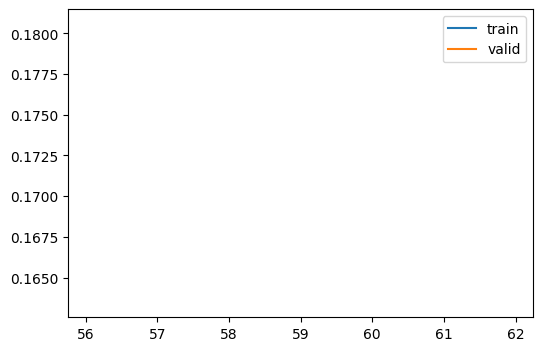

In [32]:
p1,t1 = learn.capture_preds()

accuracy,loss,epoch,train
94.430,0.172,0,eval


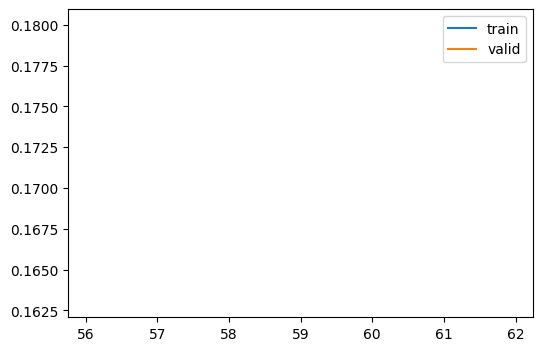

In [33]:
ttacb = BatchTransformCB(partial(tfm_batch, t_x=TF.hflip), on_val=True)
p2,t2 = learn.capture_preds(cbs=ttacb)

In [34]:
p1.shape,p2.shape,t1.shape,t2.shape

(torch.Size([10000, 10]),
 torch.Size([10000, 10]),
 torch.Size([10000]),
 torch.Size([10000]))

In [35]:
torch.stack([p1,p2]).shape

torch.Size([2, 10000, 10])

In [36]:
(((p1+p2)/2).argmax(1) == torch.stack([p1,p2]).mean(0).argmax(1)).to(float).sum()

tensor(10000., dtype=torch.float64)

same thing

In [37]:
final_p = torch.stack([p1,p2]).mean(0).argmax(1)

In [38]:
# check with the labels to see the acc
round((final_p==t1).float().mean().item(),4)*100

94.63000000000001

# Random Erase

In [39]:
xb,_ = next(iter(dls.train))
xbb = xb[:16]

In [40]:
xbb.shape

torch.Size([16, 1, 28, 28])

In [41]:
xm, xs = xbb.mean(), xbb.std()

In [42]:
xbb.min(), xbb.max()

(tensor(-0.80), tensor(2.06))

In [43]:
# how much of the image size (r)
r = 0.2

In [44]:
# size of the block
szx = int(r*xbb.shape[-2])
szy = int(r*xbb.shape[-1])
# start point
stx = int(random.random()*(1-r)*xbb.shape[-2]) # (1-r) to make sure we dont get out of dims
sty = int(random.random()*(1-r)*xbb.shape[-1])
stx,sty,szx,szy

(14, 0, 5, 5)

In [45]:
int(random.random()*100) # random.random() give decimals 0 -> 1

27

In [46]:
init.normal_(xbb[:,:,stx:stx+szx,sty:sty+szy], mean=xm, std=xs); # make the noise -with same std and mean [inplace]

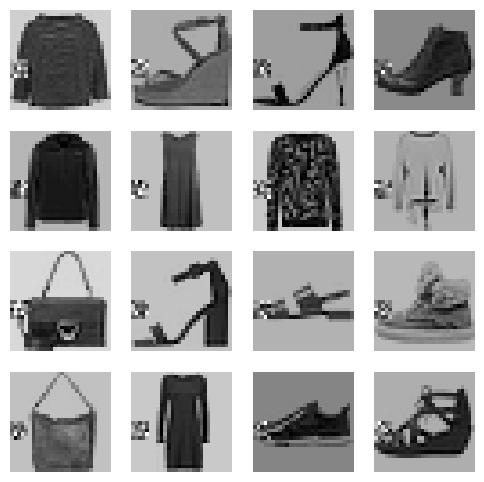

In [47]:
show_images(xbb, imsize=1.5)

In [48]:
xbb.min(), xbb.max() # we can see it change from (tensor(-0.80), tensor(2.06)) to ->

(tensor(-3.42), tensor(2.74))

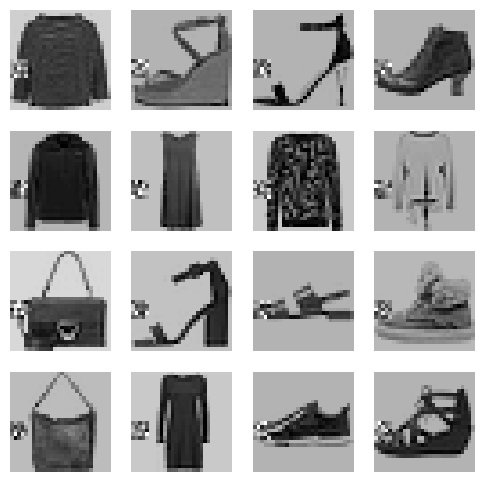

In [49]:
xbb.clamp_(-2,2.4)
show_images(xbb, imsize=1.5)

In [50]:
def _rand_erase1(x, r, xm, xs, mn, mx):
    szx = int(r*x.shape[-2])
    szy = int(r*x.shape[-1])
    stx = int(random.random()*(1-r)*x.shape[-2])
    sty = int(random.random()*(1-r)*x.shape[-1])
    init.normal_(x[:,:,stx:stx+szx,sty:sty+szy], mean=xm, std=xs)
    x.clamp_(mn, mx)

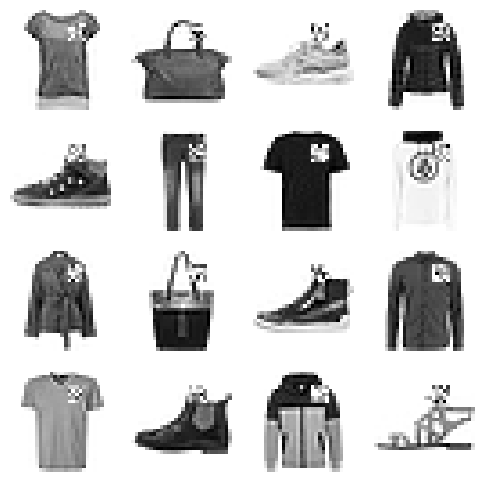

In [51]:
xb,_ = next(iter(dls.train))
xbt = xb[:16]
_rand_erase1(xbt, 0.2, xbt.mean(), xbt.std(), xbt.min(), xbt.max())
show_images(xbt, imsize=1.5)

In [52]:
xbt.mean(),xbt.std(),xbt.min(), xbt.max()

(tensor(-0.03), tensor(0.97), tensor(-0.80), tensor(2.06))

In [53]:
# make a function that makes more than one
def rand_erase(x, r=0.2, max_num=4):
    xm,xs,mn,mx = x.mean(),x.std(),x.min(),x.max()
    num = random.randint(0, max_num)
    for i in range(num): _rand_erase1(x, r, xm, xs, mn, mx)
    return x

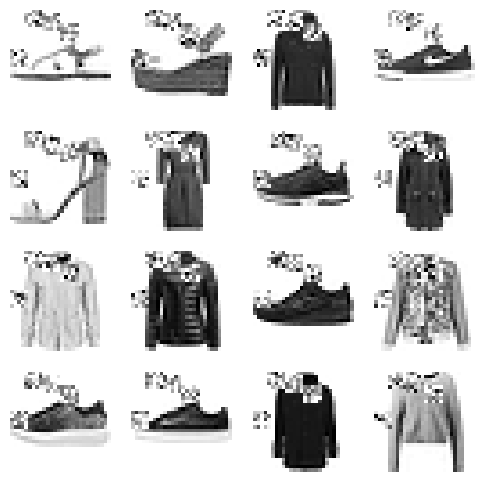

In [54]:
xb,_ = next(iter(dls.train))
xbt = xb[:16]
rand_erase(xbt, 0.2, 4)
show_images(xbt, imsize=1.5)

In [55]:
# make it as a class
class RandErase(nn.Module):
    def __init__(self, r=0.2, max_num=4):
        super().__init__()
        self.r,self.max_num = r,max_num
    def forward(self, x): return rand_erase(x, self.r, self.max_num)

In [56]:
tfms = nn.Sequential(transforms.RandomCrop(28, padding=1),
                     transforms.RandomHorizontalFlip(),
                     RandErase())
augcb = BatchTransformCB(partial(tfm_batch, t_x=tfms), on_val=False)

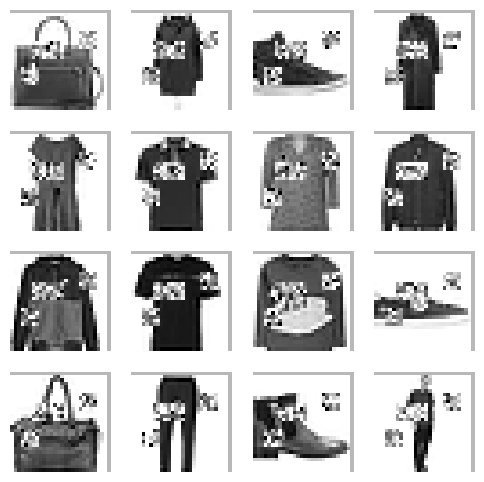

In [57]:
# lets see how the images can look like
model = get_model()
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=[DeviceCB(), SingleBatchCB(), augcb])
learn.fit(1)
xb,yb = learn.batch
show_images(xb[:16], imsize=1.5)

accuracy,loss,epoch,train
75.260,0.908,0,train
82.720,0.588,0,eval
84.315,0.625,1,train
85.290,0.537,1,eval
86.302,0.530,2,train
86.270,0.453,2,eval
87.033,0.466,3,train
87.830,0.404,3,eval
87.508,0.414,4,train
88.850,0.343,4,eval


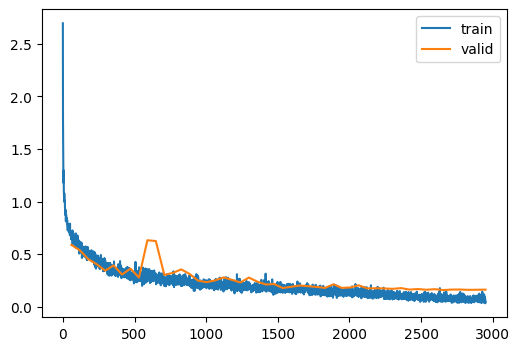

In [58]:
# we can train now for 50 epochs
epochs , lr = 50 , 2e-2
tmax = epochs*len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
model = get_model(act_gr,norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

# Random Copy

In [59]:
xb,_ = next(iter(dls.train))
xbt = xb[:16]

In [60]:
pct=0.2

In [61]:
szx = int(pct*xbt.shape[-2])
szy = int(pct*xbt.shape[-1])
stx1 = int(random.random()*(1-pct)*xbt.shape[-2])
sty1 = int(random.random()*(1-pct)*xbt.shape[-1])
stx2 = int(random.random()*(1-pct)*xbt.shape[-2])
sty2 = int(random.random()*(1-pct)*xbt.shape[-1])
stx1,sty1,stx2,sty2,szx,szy

(21, 14, 22, 15, 5, 5)

In [62]:
xbt[:,:,stx1:stx1+szx,sty1:sty1+szy] = xbt[:,:,stx2:stx2+szx,sty2:sty2+szy]

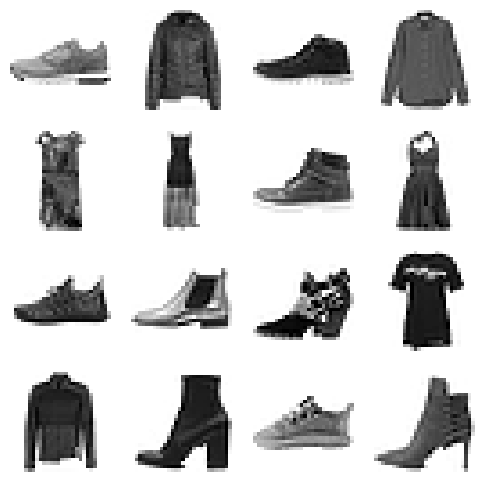

In [63]:
show_images(xbt, imsize=1.5)

In [64]:
def _rand_copy1(x, pct):
    szx = int(pct*x.shape[-2])
    szy = int(pct*x.shape[-1])
    stx1 = int(random.random()*(1-pct)*x.shape[-2])
    sty1 = int(random.random()*(1-pct)*x.shape[-1])
    stx2 = int(random.random()*(1-pct)*x.shape[-2])
    sty2 = int(random.random()*(1-pct)*x.shape[-1])
    x[:,:,stx1:stx1+szx,sty1:sty1+szy] = x[:,:,stx2:stx2+szx,sty2:sty2+szy]

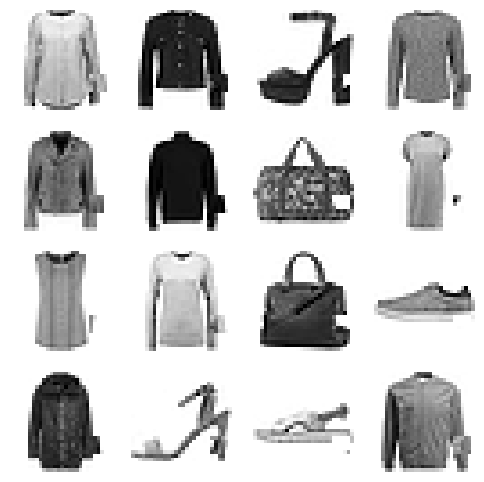

In [65]:
xb,_ = next(iter(dls.train))
xbt = xb[:16]
_rand_copy1(xbt, 0.2)
show_images(xbt, imsize=1.5)

In [66]:
def rand_copy(x, pct=0.2, max_num = 4):
    num = random.randint(0, max_num)
    for i in range(num): _rand_copy1(x, pct)
    return x

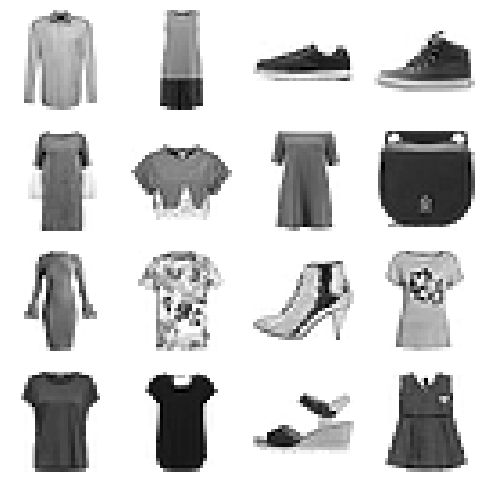

In [67]:
xb,_ = next(iter(dls.train))
xbt = xb[:16]
rand_copy(xbt, 0.2, 4)
show_images(xbt, imsize=1.5)

In [68]:
# Make it as class
class RandCopy(nn.Module):
    def __init__(self, pct=0.2, max_num=4):
        super().__init__()
        self.pct,self.max_num = pct,max_num
    def forward(self, x): return rand_copy(x, self.pct, self.max_num)

In [69]:
tfms = nn.Sequential(transforms.RandomCrop(28, padding=1),
                     transforms.RandomHorizontalFlip(),
                     RandCopy())
augcb = BatchTransformCB(partial(tfm_batch, t_x=tfms), on_val=False)

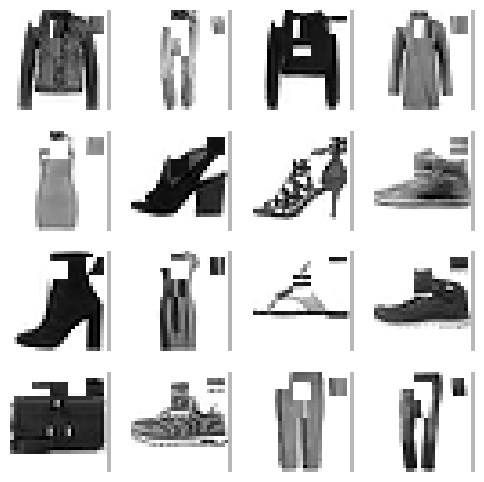

In [70]:
model_trial = get_model()
learn_trial = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=[DeviceCB(), SingleBatchCB(), augcb])
learn_trial.fit(1)
xb,yb = learn_trial.batch
show_images(xb[:16], imsize=1.5)

accuracy,loss,epoch,train
74.285,0.935,0,train
81.990,0.596,0,eval
83.928,0.653,1,train
81.770,0.589,1,eval
84.787,0.573,2,train
85.000,0.482,2,eval
85.823,0.490,3,train
85.600,0.440,3,eval
86.953,0.420,4,train
85.240,0.423,4,eval


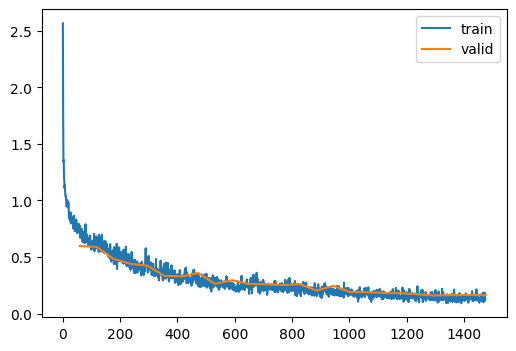

In [71]:
epochs = 25
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
model2 = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn2 = TrainLearner(model2, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn2.fit(epochs)

accuracy,loss,epoch,train
73.528,0.950,0,train
80.670,0.634,0,eval
83.390,0.663,1,train
77.860,0.758,1,eval
85.425,0.558,2,train
81.490,0.565,2,eval
85.882,0.489,3,train
82.060,0.537,3,eval
87.107,0.415,4,train
84.170,0.482,4,eval


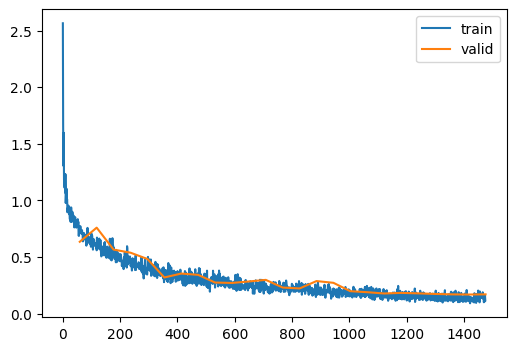

In [72]:
model3 = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn3 = TrainLearner(model3, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn3.fit(epochs)

Make a ENSEMBLE of the 2 models , they trained with same cbs,etc... , but diff randomness

accuracy,loss,epoch,train
94.390,0.163,0,eval


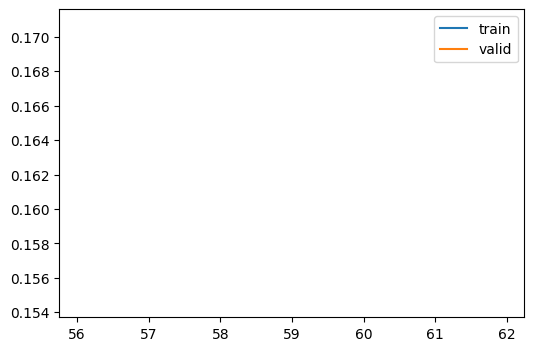

In [73]:
cp1 = Capture_preds()
learn2.fit(1, train=False, cbs=cp1)

accuracy,loss,epoch,train
94.210,0.169,0,eval


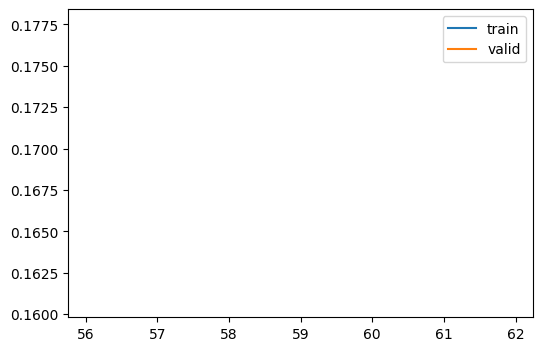

In [74]:
cp2 = Capture_preds()
learn3.fit(1, train=False, cbs=cp2)

In [75]:
ap = torch.stack([cp1.preds,cp2.preds]).mean(0).argmax(1)

In [76]:
round((ap==cp1.targs).float().mean().item(), 3)*100

94.69999999999999

# Dropout

    ACTUAL MATH: WHAT CO-ADAPTATION IS
    ─────────────────────────────────────────
    simple network, one hidden layer, two neurons:

        input x = 0.8

        h1 = w1 * x = 0.6 * 0.8 = 0.48
        h2 = w2 * x = 0.4 * 0.8 = 0.32

        output = w3*h1 + w4*h2
               = 2.0*0.48 + 3.0*0.32
               = 0.96 + 0.96
               = 1.92

        target = 2.0
        loss   = (2.0 - 1.92)² = 0.0064


    ─────────────────────────────────────────
    BACKPROP WITHOUT DROPOUT
    ─────────────────────────────────────────
    gradient flows back to w1 and w2:

        d(loss)/d(w3) depends on h1
        d(loss)/d(w4) depends on h2
        d(loss)/d(w1) depends on w3
        d(loss)/d(w2) depends on w4

        w1 update uses w3's current value
        w2 update uses w4's current value
        w3 update uses h1's current value
        w4 update uses h2's current value

    THEY ARE ALL UPDATING BASED ON EACH OTHER

    after 1000 steps maybe:
        w1 = 0.1  (became weak)
        w2 = 0.9  (became strong)
        w3 = 0.3  (adjusted to w1 being weak)
        w4 = 2.8  (adjusted to w2 being strong)

        output = 0.3*0.08 + 2.8*0.72
               = 0.024 + 2.016
               = 2.04  ← close to target ✓

    BUT NOW REMOVE h2 at inference (imagine):
        output = 0.3*0.08 + 0
               = 0.024   ← COMPLETELY WRONG ✗

    w1 and w3 became useless
    because the optimizer found a solution
    where w2 and w4 do ALL the work
    and w1 and w3 just exist as passengers

    this is co-adaptation:
    the WEIGHTS numerically settled into values
    that only work as a team
    individually they are useless ✗


    ─────────────────────────────────────────
    BACKPROP WITH DROPOUT
    ─────────────────────────────────────────
    pass 1: h2 killed by mask
        output = w3*h1 + 0
        loss = (target - w3*h1)²
        gradient forces w1 and w3 to carry EVERYTHING alone
        w1 and w3 update to become strong ✓

    pass 2: h1 killed by mask
        output = 0 + w4*h2
        loss = (target - w4*h2)²
        gradient forces w2 and w4 to carry EVERYTHING alone
        w2 and w4 update to become strong ✓

    pass 3: neither killed
        both contribute honestly ✓

    after 1000 steps:
        w1 = 0.5  (genuinely strong)
        w2 = 0.5  (genuinely strong)
        w3 = 2.0  (genuinely strong)
        w4 = 2.0  (genuinely strong)

        each pair works alone:
        output with only h1 = 2.0*0.4 = 0.8  reasonable ✓
        output with only h2 = 2.0*0.4 = 0.8  reasonable ✓
        output with both    = 1.6            close to target ✓


    ─────────────────────────────────────────
    WHY SCALING CONNECTS TO THIS
    ─────────────────────────────────────────
    during training with dropout p=0.5:
        on average only 1 neuron alive out of 2
        w3 and w4 learned: "i must output ~2.0 alone"
        so each outputs 2.0 when active

    during inference, BOTH alive:
        output = 2.0*h1 + 2.0*h2
               = 2.0*0.4 + 2.0*0.4
               = 1.6  ← bigger than expected ✗

    scaling * 1/(1-p) = * 2 during training:
        forces each neuron to output 4.0 when active

        at inference both alive, no scaling:
        output = 4.0*h1*0.5 + 4.0*h2*0.5
        wait no

    correct version:
        during training * 1/(1-0.5) = * 2
        active neuron output gets doubled

        inference: both alive, no mask, no scaling
        output = 2.0*h1 + 2.0*h2 = same expected value ✓


In [77]:
p = 0.1
dist = distributions.binomial.Binomial(probs=1-p)
dist.sample((10,))

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 0.])

- dead = p
- alive = 1-p

In [78]:
class Dropout(nn.Module):
    def __init__(self,p):
        super().__init__()
        self.p = p
    def forward(self,x): # x is the input [mostly the activations from another layer before it]
        if not self.training : return x
        dist = distributions.binomial.Binomial(tensor(1.0).to(x.device),probs=1-self.p)
        return x * dist.sample(x.size()) * 1/(1-self.p) # * 1/(1-self.p) is for scale

- Binomial(1,  0.9) → each neuron gets: 0 or 1 [we make 1(float) -> tensor(1.0) to work with torch]
- Binomial(10, 0.9) → each neuron gets: 0,1,2,3,4,5,6,7,8,9,10

at bionomial dist:
- Not guaranteed exact 90% of total neuron are dead, just each neuron independently has 90% survival chance. With large layers it averages out close to 90%.

In [79]:
def get_dropmodel(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d, drop=0.0):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm), nn.Dropout2d(drop)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), Dropout(drop), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

In [80]:
epochs=5
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
model4 = get_dropmodel(act_gr, norm=nn.BatchNorm2d, drop=0.1).apply(iw)
learn4 = TrainLearner(model4, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

In [ ]:
learn4.fit(epochs)

In [ ]:
class TTD_CB(Callback): # Test Time Dropout Callback
    def before_epoch(self,learn):
        learn.model.apply(lambda layer : layer.train() if isinstance(layer, (nn.Dropout,nn.Dropout2d)) else None)

    normally in PyTorch:
        model.train() → dropout IS active
        model.eval()  → dropout is DISABLED [during validation PyTorch calls eval()
                                             so dropout turns off automatically]

    TTD_CB forces dropout to stay in train mode
    even during validation

    WHY:
        keeping dropout ON during inference
        gives different prediction every forward pass
        run it 10 times → 10 slightly different predictions
        average them → more robust prediction
        this is called MC Dropout (Monte Carlo Dropout) ✓

    nn.Module
        ↓ inherits
    nn.Dropout

    nn.Module gives EVERY layer these methods:
        .train()  → sets self.training = True
        .eval()   → sets self.training = False

In [ ]:
@inplace
def transformi(b): b[xl] = [(TF.to_tensor(o)*2-1) for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

    old transform:
        TF.to_tensor(o)          → values in [0, 1]

    new transform:
        TF.to_tensor(o) * 2 - 1  → values in [-1, 1]

    WHY:
       [0, 1] → mean is ~0.5, not centered ✗
       [-1, 1] → mean is ~0.0, centered ✓ -> centered inputs → better gradient flow,etc

    -------------------

    pixels in real life:    0   → 255  (uint8)
    after to_tensor:        0.0 → 1.0  (float)
    after *2-1:            -1.0 → 1.0  (float)

    for TRAINING:   [-1, 1] is fine, better even ✓
    for PLOTTING:   show_image expects [0, 1] or [0, 255]
                    [-1, 1] will look wrong ✗ , like we cant plot the learn.batch
                    after an epoch

    Solution:
    - transform was: x * 2 - 1  ,  reverse is:  (x + 1) / 2
    - use the original ds

In [ ]:
epochs = 20
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), augcb]
model5 = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn5 = TrainLearner(model5, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn5.fit(epochs)

# My own CosineLRSched and OnecycleLRSched

In [ ]:
import math
pi = math.pi

In [ ]:
class CosineLRSched():
    def __init__(self,total_steps):
        self.inc = pi/total_steps
        self.para = 0
        self.start = True
    def sched_step(self,learn):
        if self.start:
            self.start = False
            self.base_lr = learn.opt.param_groups[0]['lr']

        learn.opt.param_groups[0]['lr'] =self.base_lr * (torch.cos(tensor(self.para))+1)/2
        self.para += self.inc
        self.last_lr = learn.opt.param_groups[0]['lr']


In [ ]:
class OnecycleLRSched(): # for sgd
    def __init__(self,total_steps):
        self.inc = pi/(total_steps)
        self.para = 0
        self.start = True
    def sched_step(self,learn):
        if self.start:
            self.start = False
            self.base_lr = learn.opt.param_groups[0]['lr']
            self.base_mom = learn.opt.param_groups[0]['momentum']

        learn.opt.param_groups[0]['lr'] =self.base_lr * torch.sin(tensor(self.para))
        learn.opt.param_groups[0]['momentum']=self.base_mom - (1-self.base_mom)*torch.sin(tensor(self.para))
        self.para += self.inc
        self.last_lr = learn.opt.param_groups[0]['lr']
        self.last_mom = learn.opt.param_groups[0]['momentum']

In [ ]:
class dummyOpt:
    def __init__(self, lr, momentum):
        self.param_groups = [{'lr': lr, 'momentum': momentum}]

class dummyLearn:
    def __init__(self, lr, momentum):
        self.opt = dummyOpt(lr, momentum)

In [ ]:
total_steps = 300
dummy_learn = dummyLearn(lr=0.06, momentum=0.95)

In [ ]:
# cosine
dummy_sched = CosineLRSched(total_steps)
lrs = []
for _ in range(total_steps):
    dummy_sched.sched_step(dummy_learn)
    lrs.append(dummy_sched.last_lr)

plt.figure(figsize=(10,3))
plt.plot(lrs, label='lr')
plt.title('Cosine LR Schedule')
plt.legend()
plt.show()

In [ ]:
# onc cycle
dummy_learn = dummyLearn(lr=0.06, momentum=0.95)
dummy_sched = OnecycleLRSched(total_steps)

lrs, moms = [], []
for _ in range(total_steps):
    dummy_sched.sched_step(dummy_learn)
    lrs.append(dummy_sched.last_lr)
    moms.append(dummy_sched.last_mom)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,6))
ax1.plot(lrs,  label='lr')
ax2.plot(moms, label='momentum')
ax1.legend()
ax2.legend()
plt.title('One Cycle Schedule')
plt.tight_layout()
plt.show()

# Making my own experiments

## 1

In [108]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

accuracy,loss,epoch,train
83.162,0.694,0,train
87.140,0.446,0,eval
89.648,0.386,1,train
88.880,0.349,1,eval
91.955,0.273,2,train
90.740,0.289,2,eval
94.053,0.201,3,train
92.540,0.237,3,eval
96.162,0.144,4,train
92.790,0.230,4,eval


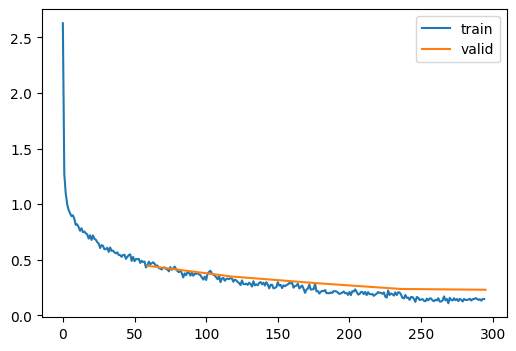

In [109]:
epochs = 5
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

learn.fit(epochs)

## 2

In [110]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d, drop=0.0):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm), nn.Dropout2d(drop)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), Dropout(drop), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

accuracy,loss,epoch,train
81.338,0.738,0,train
86.810,0.451,0,eval
89.242,0.394,1,train
88.240,0.368,1,eval
91.580,0.277,2,train
91.160,0.277,2,eval
93.602,0.210,3,train
91.910,0.243,3,eval
95.487,0.160,4,train
92.860,0.224,4,eval


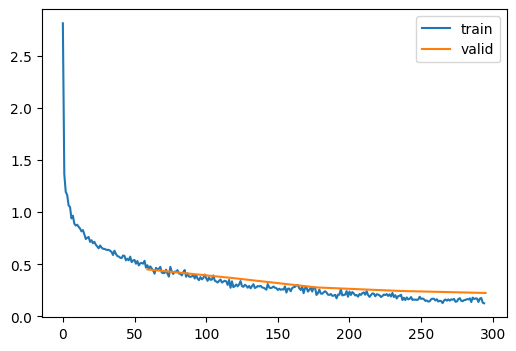

In [111]:
epochs = 5
lr = 1e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
model = get_model(act_gr, norm=nn.BatchNorm2d,drop=0.1).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

learn.fit(epochs)

## 3

In [112]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d, drop1=0.2):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    for i in range(len(nfs)-1):
        if nfs[i] == 64: layers += [nn.Dropout2d(drop1)]
        layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2)]
    layers += [nn.Flatten(), Dropout(drop1), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

In [113]:
def experiment(epochs=5,lr = 1e-2,*args,**kwargs):
    epochs = 5
    lr = 1e-2
    tmax = epochs * len(dls.train)
    sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
    xtra = [BatchSchedCB(sched)]
    model = get_model(act_gr, norm=nn.BatchNorm2d,*args,**kwargs).apply(iw)
    learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
    learn.fit(epochs)

accuracy,loss,epoch,train
81.083,0.747,0,train
85.500,0.496,0,eval
89.252,0.398,1,train
89.330,0.336,1,eval
91.725,0.278,2,train
91.070,0.276,2,eval
93.590,0.213,3,train
92.350,0.235,3,eval
95.222,0.167,4,train
93.060,0.222,4,eval


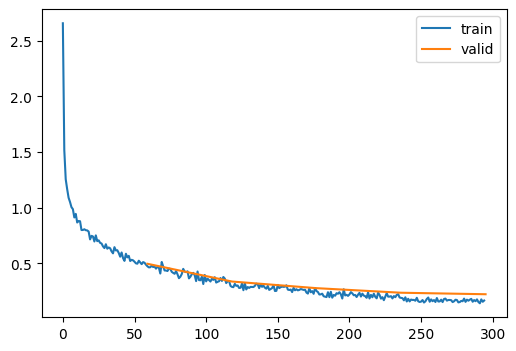

In [114]:
experiment(drop1=0.2)

## 4

In [115]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d, drop1=0.2,drop2=0.3):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    for i in range(len(nfs)-1):
        if nfs[i] == 256: layers += [nn.Dropout2d(drop2)]
        layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2)]
    layers += [nn.Flatten(), Dropout(drop1), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

accuracy,loss,epoch,train
81.152,0.751,0,train
86.700,0.462,0,eval
89.455,0.393,1,train
89.270,0.344,1,eval
91.777,0.277,2,train
90.850,0.287,2,eval
93.882,0.206,3,train
92.640,0.235,3,eval
95.913,0.149,4,train
92.940,0.224,4,eval


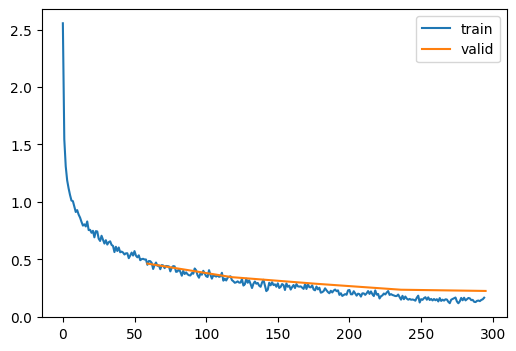

In [116]:
experiment(drop2=0.3)

## 5

accuracy,loss,epoch,train
80.382,0.769,0,train
80.710,0.685,0,eval
88.812,0.412,1,train
89.490,0.337,1,eval
91.193,0.294,2,train
90.060,0.302,2,eval
92.910,0.232,3,train
92.040,0.247,3,eval
94.512,0.185,4,train
92.240,0.234,4,eval


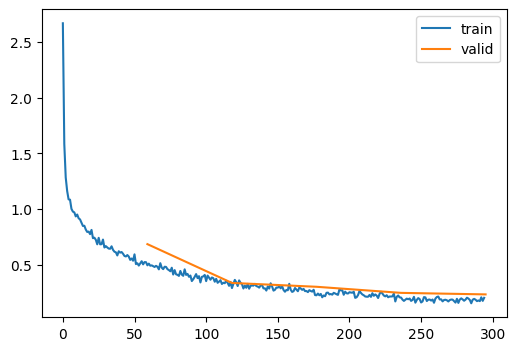

In [117]:
def get_model(act=nn.ReLU, nfs=(16, 32, 64, 128, 256, 512), norm=nn.BatchNorm2d, drop1=0.2, drop2=0.3):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    for i in range(len(nfs) - 1):
        if nfs[i] == 64: layers += [nn.Dropout2d(drop1)]
        if nfs[i] == 256: layers += [nn.Dropout2d(drop2)]
        layers += [ResBlock(nfs[i], nfs[i + 1], act=act, norm=norm, stride=2)]
    layers += [nn.Flatten(), Dropout(drop1), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)


experiment(drop2=0.3)

## 6

accuracy,loss,epoch,train
76.663,0.846,0,train
84.690,0.518,0,eval
88.085,0.424,1,train
86.360,0.464,1,eval
90.695,0.306,2,train
88.150,0.344,2,eval
92.828,0.234,3,train
91.680,0.254,3,eval
94.528,0.186,4,train
92.540,0.233,4,eval


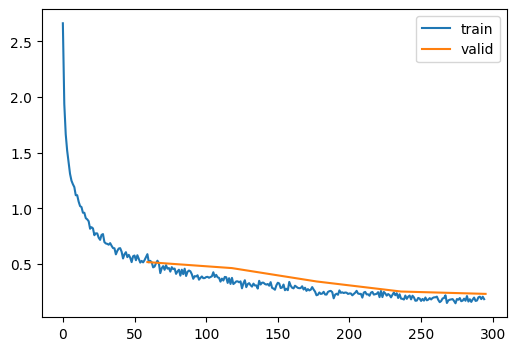

In [118]:
def get_model(act=nn.ReLU, nfs=(16, 32, 64, 128 ,128, 256, 512), norm=nn.BatchNorm2d, drop1=0.2, drop2=0.5):
    m=0
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]

    for i in range(len(nfs[0:4])):
        if nfs[i] == 64: layers += [nn.Dropout2d(drop1)]
        layers += [ResBlock(nfs[m], nfs[m + 1], act=act, norm=norm, stride=2)]
        m +=1

    layers += [ResBlock(128, 128, ks=5, stride=1, act=act, norm=norm)]
    layers += [nn.Dropout2d(p=drop2)]

    for i in range(len(nfs[4:])-1):
        layers += [ResBlock(nfs[m], nfs[m + 1], act=act, norm=norm, stride=2)]
        m+=1

    layers += [nn.Flatten(), Dropout(drop1), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)


experiment()